<a href="https://colab.research.google.com/github/KrithikChidM/PrmlLab/blob/main/Lab6/code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)

n = 5000
K = 3
weights = np.array([0.5, 0.3, 0.2])

In [13]:
class KMeans:
    def __init__(self, K=3):
        self.K = K
        self.centers = None

    def fit(self, X):
        rng = np.random.default_rng(42)
        indices = rng.choice(len(X), size=self.K, replace=False)
        self.centers = X[indices].astype(float)

        for _ in range(100):
            labels = self.predict(X)
            new_centers = self.centers.copy()

            for k in range(self.K):
                points = X[labels == k]
                if len(points) > 0:
                    new_centers[k] = points.mean(axis=0)

            converged = np.max(np.abs(self.centers - new_centers)) < 1e-6
            self.centers = new_centers
            if converged:
                break

        return self

    def predict(self, X):
        if self.centers is None:
            raise ValueError("Call fit() before predict().")

        labels = []
        for point in X:
            distances = [np.sum((point - center) ** 2) for center in self.centers]
            labels.append(np.argmin(distances))

        return np.array(labels, dtype=int)

In [2]:
means = np.array([[-1.0, -3.5], [0.0, 0.0], [1.0, 3.5]])
means_2 = means + np.array([4.0, 0.0])
class_means = [means, means_2]

covariances = [
    np.array([[1.0, 0.6], [0.6, 1.0]]),
    np.eye(2),
    np.diag([1.5, 0.5])
]

covariances_2 = [
    np.array([[1.0, -0.6], [-0.6, 1.0]]),
    np.eye(2),
    np.array([[1.5, -0.5], [-0.5, 0.5]])
]

class_covariances = [covariances, covariances_2]

covariance_names = [
    ["Full (+tilt)", "Isotropic", "Diagonal"],
    ["Full (-tilt)", "Isotropic", "Full (-tilt)"]
]

In [3]:
def uniform():
    return max(random.random(), 1e-12)

def box_muller():
    u1 = uniform()
    u2 = uniform()
    r = math.sqrt(-2 * math.log(u1))
    theta = 2 * math.pi * u2
    z1 = r * math.cos(theta)
    z2 = r * math.sin(theta)
    return z1, z2

In [4]:
def gaussian_density(x, mean, C):
    a, b = C[0]
    c, d = C[1]

    det = a*d - b*c

    dx = x[0] - mean[0]
    dy = x[1] - mean[1]

    q = (d*dx*dx - (b+c)*dx*dy + a*dy*dy) / det

    return math.exp(-0.5*q) / (2*math.pi*math.sqrt(det))

In [5]:
def gmm_density(x, means, covariances, weights):
    p = 0.0

    for i in range(K):
        p += weights[i] * gaussian_density(
            x, means[i], covariances[i]
        )

    return p

In [6]:
def generate_component(mean, C):
    z1, z2 = box_muller()

    a, b = C[0]
    c, d = C[1]

    l11 = math.sqrt(a)
    l21 = c / l11
    l22 = math.sqrt(max(d - l21*l21, 0.0))

    x1 = mean[0] + l11*z1
    x2 = mean[1] + l21*z1 + l22*z2

    return [x1, x2]

In [7]:
def generate_gmm_data(means, covariances, weights, n):
    X = []
    component_labels = []

    for _ in range(n):
        u = uniform()

        if u < weights[0]:
            k = 0
        elif u < weights[0] + weights[1]:
            k = 1
        else:
            k = 2

        x = generate_component(means[k], covariances[k])

        X.append(x)
        component_labels.append(k)

    return np.array(X), np.array(component_labels)

In [8]:
class_data = []
class_component_labels = []

for cls in range(2):
    X, component_labels = generate_gmm_data(
        class_means[cls],
        class_covariances[cls],
        weights,
        n
    )

    class_data.append(X)
    class_component_labels.append(component_labels)

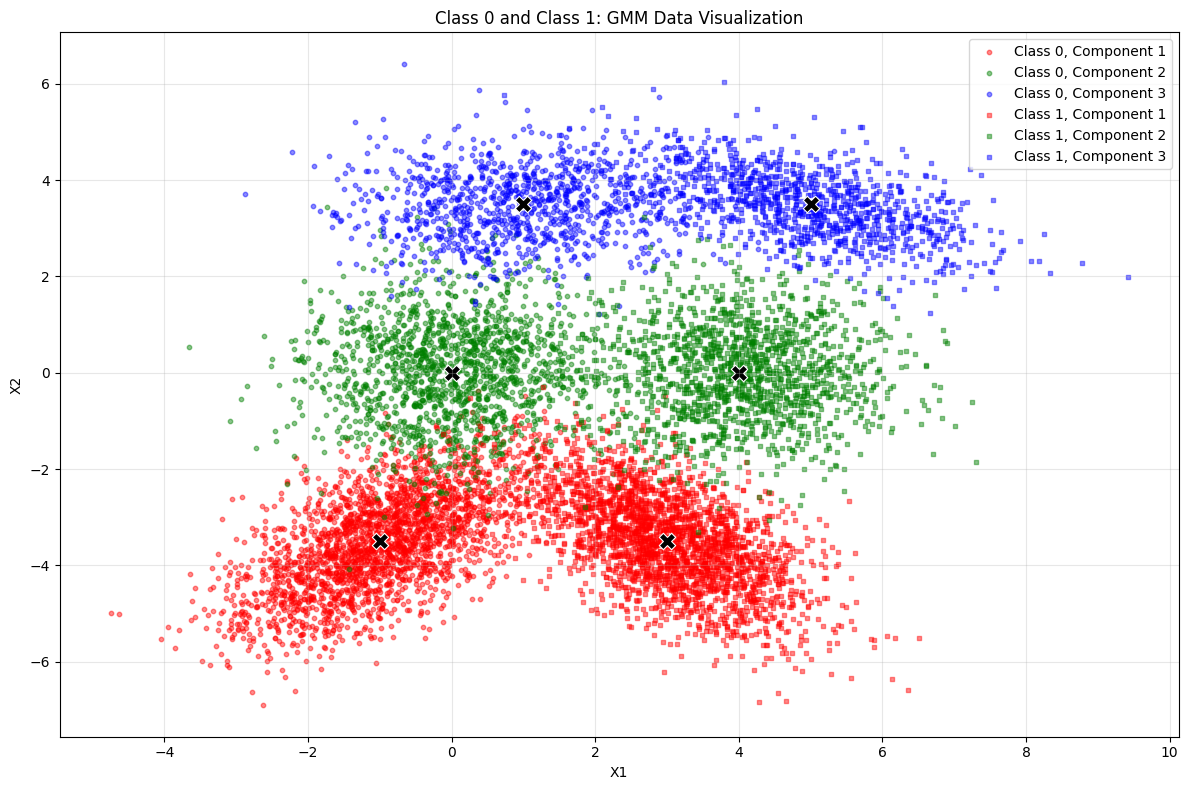

In [9]:
plt.figure(figsize=(12, 8))

colors = ["red", "green", "blue"]
markers = ["o", "s"]

for cls in range(2):
    X = class_data[cls]
    labels = class_component_labels[cls]

    for k in range(K):
        points = X[labels == k]
        plt.scatter(
            points[:, 0], points[:, 1],
            color=colors[k], marker=markers[cls],
            s=10, alpha=0.45,
            label=f"Class {cls}, Component {k + 1}"
        )

    for k in range(K):
        plt.scatter(
            class_means[cls][k][0], class_means[cls][k][1],
            color="black", marker="X", s=140,
            edgecolors="white", linewidths=0.8
        )

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Class 0 and Class 1: GMM Data Visualization")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
train_class_samples = []
test_class_samples = []

rng = np.random.default_rng(44)
train_end = int(0.8 * n)

for samples in class_data:
    shuffled = samples[np.random.default_rng().permutation(n)]
    train_class_samples.append(shuffled[:train_end])
    test_class_samples.append(shuffled[train_end:])

In [16]:
class_models = []

for class_index, samples in enumerate(train_class_samples):
    model = KMeans(K=K)
    model.fit(samples)
    class_models.append(model)
    print(f"Class {class_index + 1} centres:\n{model.centers}")

Class 1 centres:
[[-1.09394011 -3.64659114]
 [ 0.05290241 -0.19543199]
 [ 0.9741081   3.40465727]]
Class 2 centres:
[[ 3.99489852 -0.04173237]
 [ 4.92620394  3.42152814]
 [ 3.01785145 -3.50895903]]


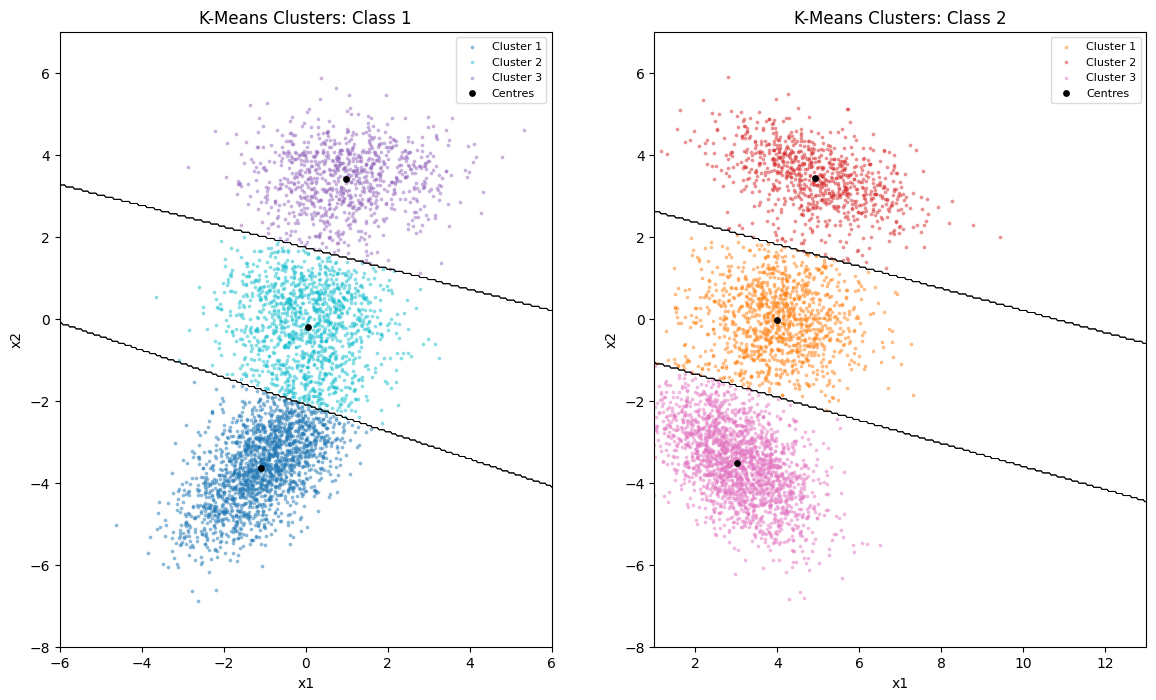

In [23]:
x_ranges = [(-6, 6), (1, 13)]
y_values = np.linspace(-8, 7, 300)
component_colors = [
    ["tab:blue", "tab:cyan", "tab:purple"],
    ["tab:orange", "tab:red", "tab:pink"]
]


plt.figure(figsize=(12, 7))
for class_index, model in enumerate(class_models):
    samples = train_class_samples[class_index]
    labels = model.predict(samples)

    x_min, x_max = x_ranges[class_index]
    x_values = np.linspace(x_min, x_max, 300)
    x_grid, y_grid = np.meshgrid(x_values, y_values)
    grid_points = np.column_stack((x_grid.ravel(), y_grid.ravel()))
    grid_labels = model.predict(grid_points).reshape(x_grid.shape)

    plt.subplot(1, 2, class_index + 1)
    for k in range(K):
        cluster = samples[labels == k]
        plt.scatter(cluster[:, 0], cluster[:, 1], s=7, alpha=0.5, linewidths=0,
                    color=component_colors[class_index][k], label=f"Cluster {k + 1}")
        plt.contour(x_grid, y_grid, grid_labels == k, levels=[0.5],
                    colors="black", linewidths=0.7)

    plt.scatter(model.centers[:, 0], model.centers[:, 1],
                marker=".", s=60, color="black", label="Centres")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"K-Means Clusters: Class {class_index + 1}")
    plt.legend(fontsize=8, framealpha=0.7)
    plt.axis("scaled")
    plt.xlim(x_min, x_max)
    plt.ylim(-8, 7)

plt.tight_layout()
plt.show()

In [20]:
test_class_predictions = []

for samples in test_class_samples:
    predictions = []
    for point in samples:
        distortions = []
        for model in class_models:
            distances = np.sum((point - model.centers) ** 2, axis=1)
            distortions.append(np.min(distances))
        predictions.append(np.argmin(distortions) + 1)
    test_class_predictions.append(np.array(predictions))

In [21]:
# rows: true class, columns: predicted class
confusion_matrix = np.zeros((2, 2), dtype=int)

for true_class, predictions in enumerate(test_class_predictions):
    for predicted_class in predictions:
        confusion_matrix[true_class, predicted_class - 1] += 1

print("Confusion matrix:\n", confusion_matrix)
print("Accuracy:", np.trace(confusion_matrix) / confusion_matrix.sum())

Confusion matrix:
 [[971  29]
 [ 52 948]]
Accuracy: 0.9595


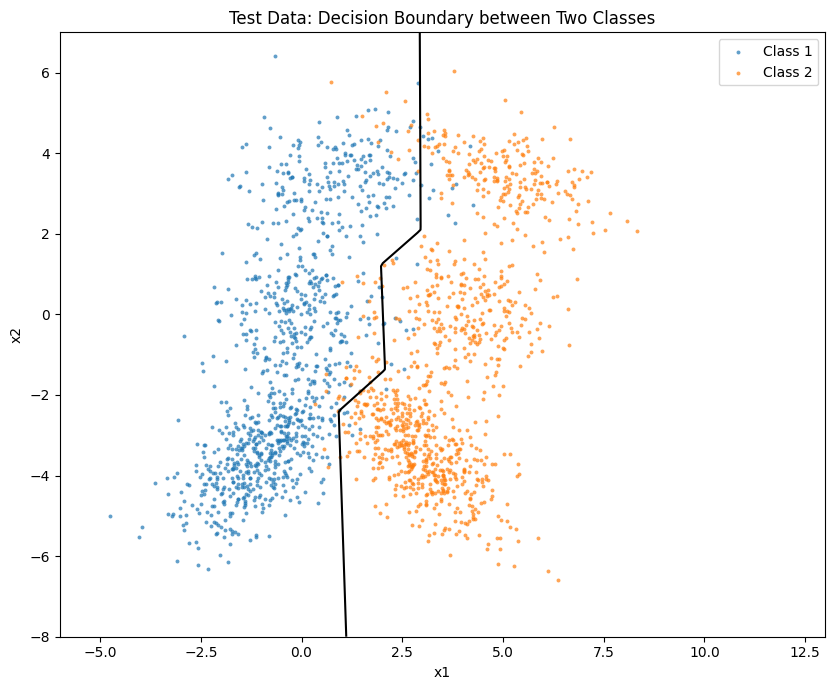

In [22]:
x_values = np.linspace(-6, 13, 200)
y_values = np.linspace(-8, 7, 200)
x_grid, y_grid = np.meshgrid(x_values, y_values)
class_distortions = []

for model in class_models:
    distances = []
    for center in model.centers:
        distances.append((x_grid - center[0]) ** 2 + (y_grid - center[1]) ** 2)
    class_distortions.append(np.min(distances, axis=0))

plt.figure(figsize=(9, 7))
for class_index, samples in enumerate(test_class_samples):
    plt.scatter(samples[:, 0], samples[:, 1], s=8, alpha=0.7, linewidths=0,
                color=component_colors[class_index][0], label=f"Class {class_index + 1}")

plt.contour(x_grid, y_grid, class_distortions[0] - class_distortions[1],
            levels=[0], colors="black")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Test Data: Decision Boundary between Two Classes")
plt.legend(fontsize=10)
plt.axis("scaled")
plt.xlim(-6, 13)
plt.ylim(-8, 7)
plt.tight_layout()
plt.show()